In [ ]:
import pandas as pd

df = pd.read_csv("/content/airlines_flights_data.csv")

df = df.sample(n = 1200, random_state = 42)

df.head()

,index,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
96277,96277,Indigo,6.00E-113,Bangalore,Morning,one,Afternoon,Mumbai,Economy,5.83,15.0,5178.0
120540,120540,Vistara,UK-774,Kolkata,Night,one,Morning,Delhi,Economy,12.00,8.0,13629.0
188544,188544,Air_India,AI-538,Chennai,Night,one,Evening,Mumbai,Economy,23.67,10.0,23208.0
20467,20467,Vistara,UK-801,Delhi,Morning,two_or_more,Evening,Kolkata,Economy,34.83,3.0,18927.0
96947,96947,Vistara,UK-812,Bangalore,Morning,one,Night,Mumbai,Economy,14.08,18.0,6568.0


In [ ]:
df.shape

(1200, 12)

In [ ]:
df.columns

Index(['index', 'airline', 'flight', 'source_city', 'departure_time', 'stops',
       'arrival_time', 'destination_city', 'class', 'duration', 'days_left',
       'price'],
      dtype='object')

In [ ]:
df = df.drop(['index', 'flight'], axis = 1)

In [ ]:
X = df.drop('price', axis = 1)

y = df['price']

In [ ]:
X = pd.get_dummies(X, drop_first = True)

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

#Linear Regression



In [ ]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()

lr.fit(X_train_scaled, y_train)

y_pred = lr.predict(X_test_scaled)

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test,y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test,y_pred)

print(f"Mean Absolute Error: {mae : .2f}")
print(f"Mean Squared Error: {mse : .2f}")
print(f"Root Mean Sqaured Error: {rmse : .2f}")
print(f"R-Sqaured: {r2 : .2f}")

Mean Absolute Error:  1824.38
Mean Squared Error:  6191146.32
Root Mean Sqaured Error:  2488.20
R-Sqaured:  0.50


#Decision Tree Regressor

In [ ]:
from sklearn.tree import DecisionTreeRegressor

dtr = DecisionTreeRegressor(random_state = 42)

from sklearn.model_selection import GridSearchCV

param_grid = {
    'criterion' : ['squared_error', 'friedman_mse', "absolute_error"],
    'max_depth' : [None, 5, 10],
    'min_samples_split' : [2, 10],
    'min_samples_leaf' : [1, 2, 4, 6]
}

grid_search = GridSearchCV(dtr, param_grid = param_grid, scoring = 'neg_root_mean_squared_error', return_train_score = True)
grid_search.fit(X_train, y_train)

print(f"Best Parameters : {grid_search.best_params_}")
print(f"Best Score: {grid_search.best_score_:.4f}")

Best Parameters : {'criterion': 'squared_error', 'max_depth': 5, 'min_samples_leaf': 6, 'min_samples_split': 2}
Best Score: -2613.5004


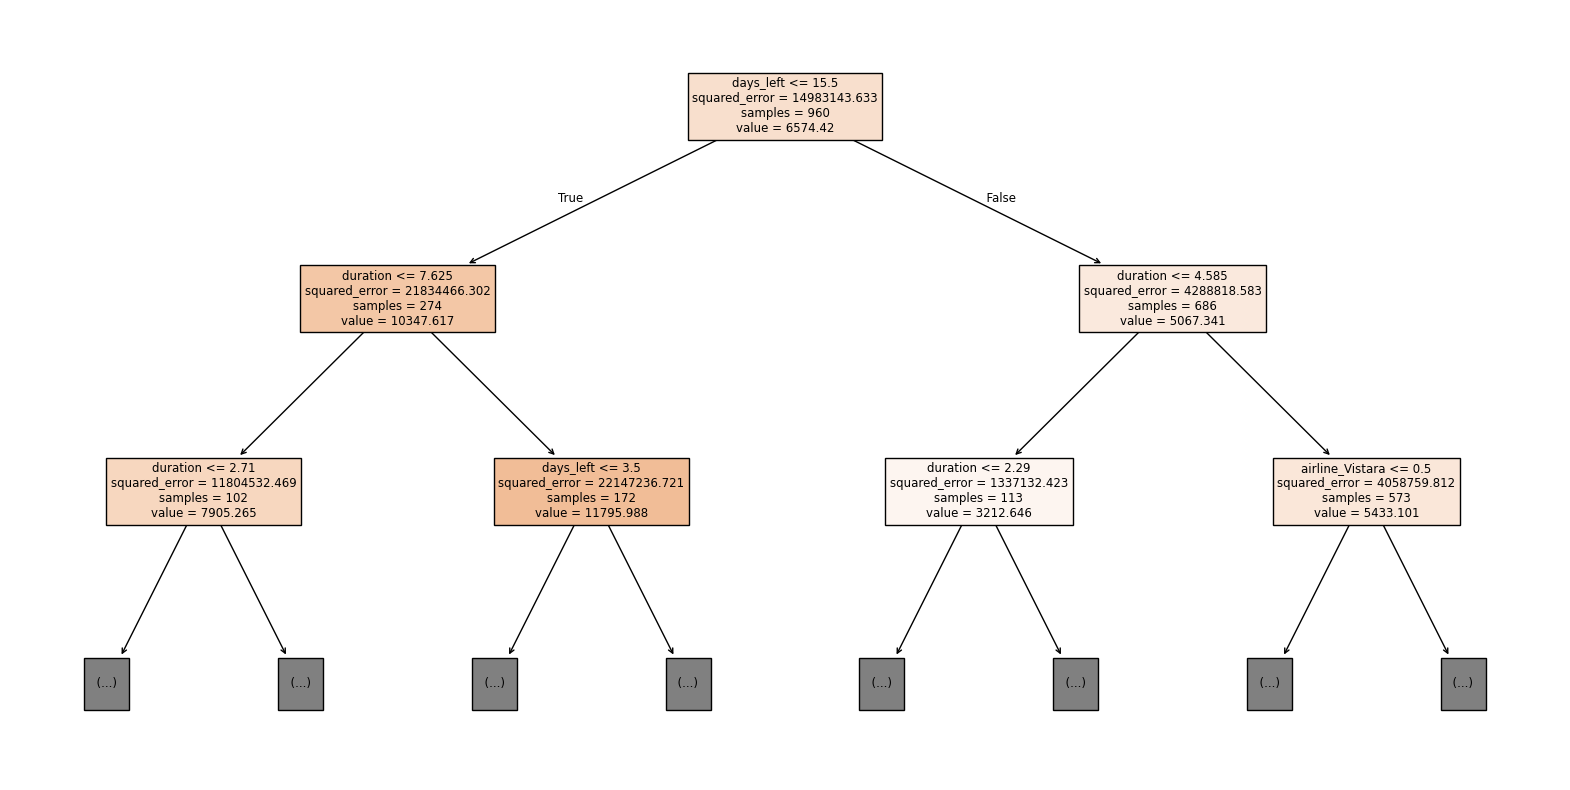

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize = (20,10))
plot_tree(
    grid_search.best_estimator_,
    feature_names = X.columns,
    max_depth = 2,
    filled = True
    )
plt.show()

In [ ]:
best_dtr = grid_search.best_estimator_

y_pred_dtr = best_dtr.predict(X_test)

mae2 = mean_absolute_error(y_test, y_pred_dtr)
mse2 = mean_squared_error(y_test, y_pred_dtr)
rmse2 = np.sqrt(mse2)
r2_2 = r2_score(y_test, y_pred_dtr)

print(f"Mean Absolute Error: {mae2 : .2f}")
print(f"Mean Squared Error: {mse2 : .2f}")
print(f"Root Mean Sqaured Error: {rmse2 : .2f}")
print(f"R-Sqaured: {r2_2 : .2f}")

Mean Absolute Error:  1619.67
Mean Squared Error:  5519775.02
Root Mean Sqaured Error:  2349.42
R-Sqaured:  0.56


#KNeighbors Regressor

In [ ]:
from sklearn.neighbors import KNeighborsRegressor

k_values = [9, 11, 14, 15, 16, 17, 19]

for k in k_values :
  knn = KNeighborsRegressor(n_neighbors = k)
  knn.fit(X_train_scaled, y_train)
  y_pred_knn = knn.predict(X_test_scaled)
  rrr = r2_score(y_test, y_pred_knn)
  print(f"k = {k}, R^2 = {rrr:.4f}")

k = 9, R^2 = 0.3302
k = 11, R^2 = 0.3283
k = 14, R^2 = 0.3073
k = 15, R^2 = 0.3261
k = 16, R^2 = 0.3134
k = 17, R^2 = 0.3221
k = 19, R^2 = 0.3211


In [ ]:
knn = KNeighborsRegressor(n_neighbors = 15)
knn.fit(X_train_scaled, y_train)
y_pred_knn = knn.predict(X_test_scaled)

mae3 = mean_absolute_error(y_test, y_pred_knn)
mse3 = mean_squared_error(y_test, y_pred_knn)
rmse3 = np.sqrt(mse3)
r2_3 = r2_score(y_test, y_pred_knn)

print(f"Mean Absolute Error: {mae3 : .2f}")
print(f"Mean Squared Error: {mse3 : .2f}")
print(f"Root Mean Sqaured Error: {rmse3 : .2f}")
print(f"R-Sqaured: {r2_3 : .2f}")

Mean Absolute Error:  2159.60
Mean Squared Error:  8379858.11
Root Mean Sqaured Error:  2894.80
R-Sqaured:  0.33
